# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")


In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("5 baris pertama:")
display(df.head())
print("Jumlah baris, kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nStatistik deskriptif:")
display(df.describe())
print("Jumlah missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())


5 baris pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris, kolom: (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


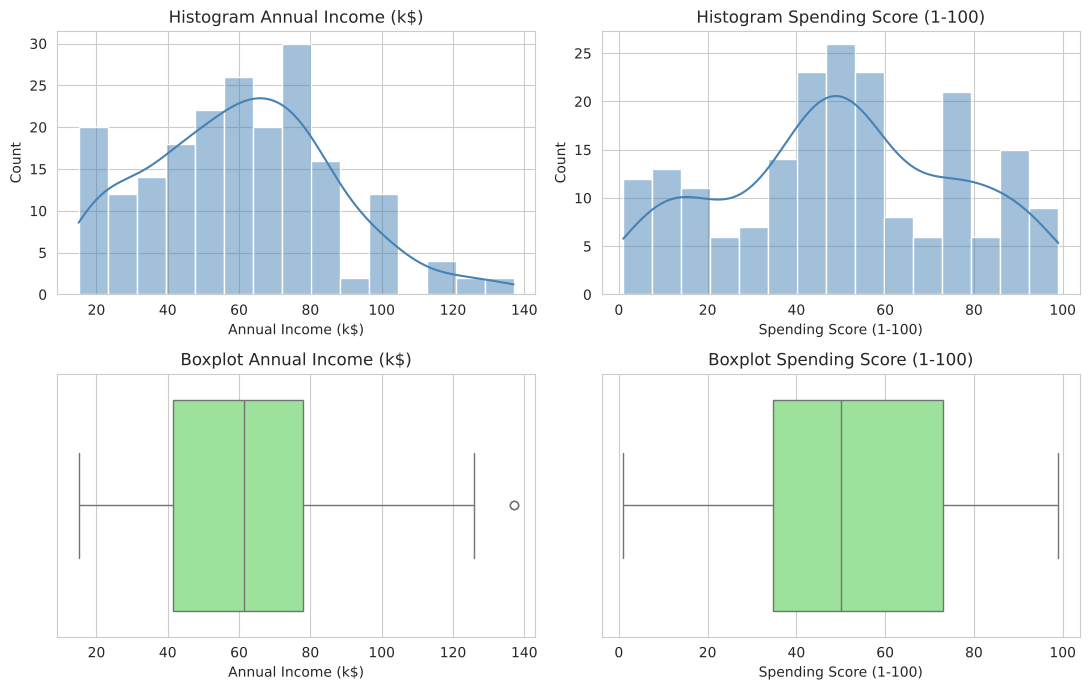

Outlier IQR pada Annual Income (k$): 2 data
Outlier IQR pada Spending Score (1-100): 0 data


In [3]:
fitur = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, f in enumerate(fitur):
    sns.histplot(df[f], bins=15, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Histogram {f}")
    sns.boxplot(x=df[f], ax=axes[1, i], color="lightgreen")
    axes[1, i].set_title(f"Boxplot {f}")
plt.tight_layout()
plt.show()

# cek outlier dengan aturan IQR
for f in fitur:
    q1, q3 = df[f].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[f] < q1 - 1.5*iqr) | (df[f] > q3 + 1.5*iqr)]
    print(f"Outlier IQR pada {f}: {len(out)} data")


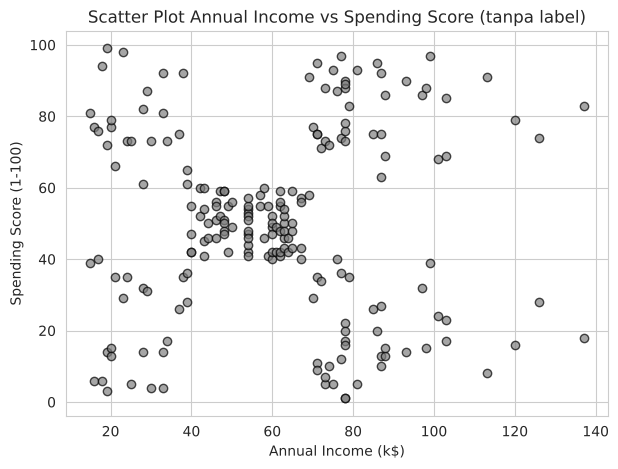

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], color="gray", edgecolor="k", alpha=0.7)
plt.title("Scatter Plot Annual Income vs Spending Score (tanpa label)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()


## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**
- Tidak ada missing value dan tidak ada baris duplikat (200 baris, 5 kolom), jadi tidak ada data yang dibuang.
- Annual Income berkisar 15 sampai 137 k$ (rata-rata 60,6 dan median 61,5), distribusinya agak miring ke kanan. Menurut aturan IQR ada 2 outlier di income (pelanggan dengan income sekitar 137 k$). Spending Score berkisar 1 sampai 99 (rata-rata 50,2 dan median 50) dengan distribusi cukup merata, tanpa outlier.
- Ya, di scatter plot terlihat sekitar 5 kelompok: satu kelompok besar di tengah (income dan spending sedang), dua kelompok di kiri (income rendah, spending tinggi dan rendah), dan dua kelompok di kanan (income tinggi, spending tinggi dan rendah). Jadi data ini memang cocok untuk clustering.

# 2. Preprocessing

In [5]:
# cek missing value dan duplikat
print("Missing value:", df.isnull().sum().sum())
print("Baris duplikat:", df.duplicated().sum())

# tidak ada missing value maupun duplikat, jadi tidak perlu ada data yang dibuang
# (kalau ada, bisa pakai df.dropna() dan df.drop_duplicates())

# ambil 2 fitur saja, CustomerID dan Gender tidak dipakai
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
print("\nBentuk X:", X.shape)
X.head()


Missing value: 0
Baris duplikat: 0

Bentuk X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("5 baris pertama X_scaled:")
display(X_scaled.head())
print("Statistik deskriptif X_scaled:")
display(X_scaled.describe().round(3))


5 baris pertama X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Statistik deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


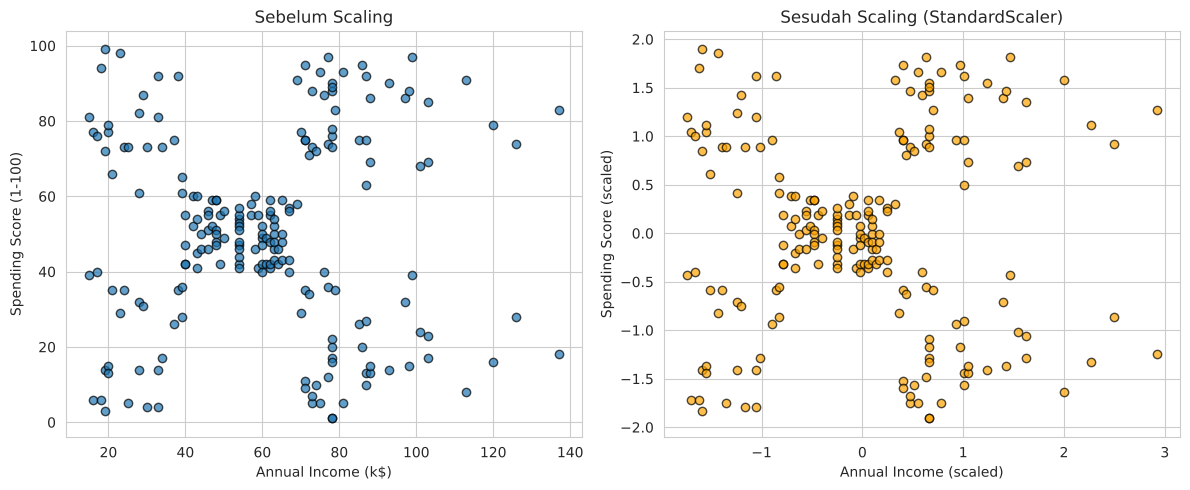

Rentang sebelum scaling:
     Annual Income (k$)  Spending Score (1-100)
min                  15                       1
max                 137                      99


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], alpha=0.7, edgecolor="k")
axes[0].set_title("Sebelum Scaling")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")

axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], alpha=0.7, edgecolor="k", color="orange")
axes[1].set_title("Sesudah Scaling (StandardScaler)")
axes[1].set_xlabel("Annual Income (scaled)")
axes[1].set_ylabel("Spending Score (scaled)")

plt.tight_layout()
plt.show()

print("Rentang sebelum scaling:")
print(X.agg(["min", "max"]))


**Mengapa scaling penting?** Algoritma yang memakai jarak (DBSCAN dengan `eps`, BIRCH dengan `threshold`) dan GMM yang memakai kovarians sangat dipengaruhi skala fitur. Fitur dengan rentang lebih besar akan mendominasi perhitungan jarak. Pada data ini rentang income (15 sampai 137) dan spending (1 sampai 99) sebenarnya masih mirip, jadi bentuk sebaran titik hampir tidak berubah setelah scaling (lihat plot di atas). Tetapi scaling tetap perlu karena StandardScaler membuat kedua fitur punya mean 0 dan standar deviasi 1, sehingga nilai `eps` dan `threshold` bisa dibandingkan dan diartikan dalam satuan standar deviasi, bukan dalam k$ atau skor.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawaban:** Kedua fitur ini dipilih karena sesuai ketentuan tugas dan paling relevan untuk segmentasi pelanggan: income menunjukkan kemampuan membeli, spending score menunjukkan perilaku belanja. Dengan dua fitur, hasil cluster juga mudah divisualisasikan dalam grafik 2D. `CustomerID` tidak dipakai karena hanya nomor urut/identitas pelanggan, tidak punya makna numerik. Kalau dimasukkan, algoritma bisa menganggap pelanggan dengan ID berdekatan itu mirip, padahal tidak ada hubungannya. `Gender` juga tidak dipakai di model utama, hanya untuk interpretasi tambahan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
print("Label unik DBSCAN:", np.unique(labels_dbscan))


Label unik DBSCAN: [-1  0  1  2  3  4  5  6]


In [9]:
print("Jumlah anggota tiap label (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts().sort_index())

n_cluster_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = (labels_dbscan == -1).sum()
print("\nJumlah cluster (tanpa noise):", n_cluster_db)
print("Jumlah noise:", n_noise_db)


Jumlah anggota tiap label (-1 = noise):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah noise: 35


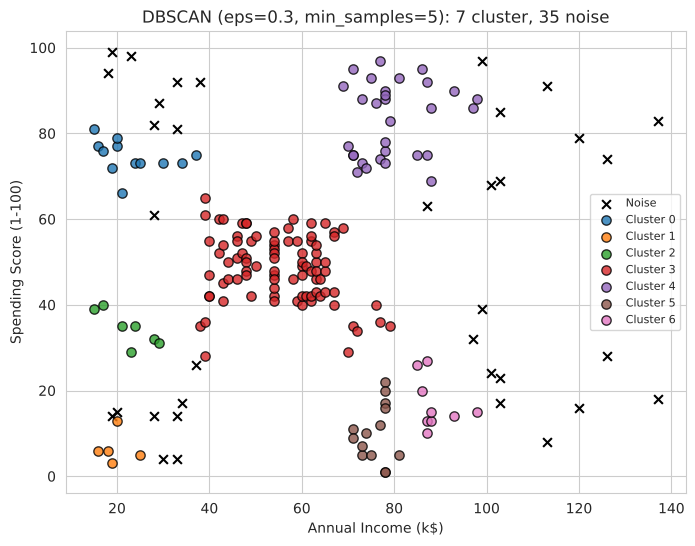

In [10]:
def plot_cluster(ax, data, labels, judul):
    """scatter plot cluster di ruang fitur asli; noise (-1) digambar silang abu-abu"""
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], c="black", marker="x", s=40, label="Noise")
        else:
            ax.scatter(data.iloc[m, 0], data.iloc[m, 1], s=45, edgecolor="k", alpha=0.8, label=f"Cluster {lab}")
    ax.set_title(judul)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend(fontsize=8, loc="best")

fig, ax = plt.subplots(figsize=(8, 6))
plot_cluster(ax, X, labels_dbscan, f"DBSCAN (eps=0.3, min_samples=5): {n_cluster_db} cluster, {n_noise_db} noise")
plt.show()


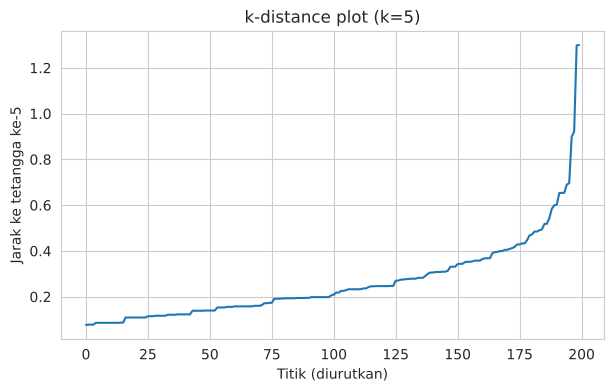

,eps,min_samples,jumlah_cluster,jumlah_noise,silhouette
0,0.2,3,13,44,0.4697
1,0.2,5,7,77,0.5856
2,0.2,8,2,116,0.6027
3,0.3,3,9,14,0.4720
4,0.3,5,7,35,0.5243
5,0.3,8,5,72,0.5926
6,0.4,3,4,10,0.3954
7,0.4,5,4,15,0.4781
8,0.4,8,5,25,0.5490
9,0.5,3,2,7,0.3892


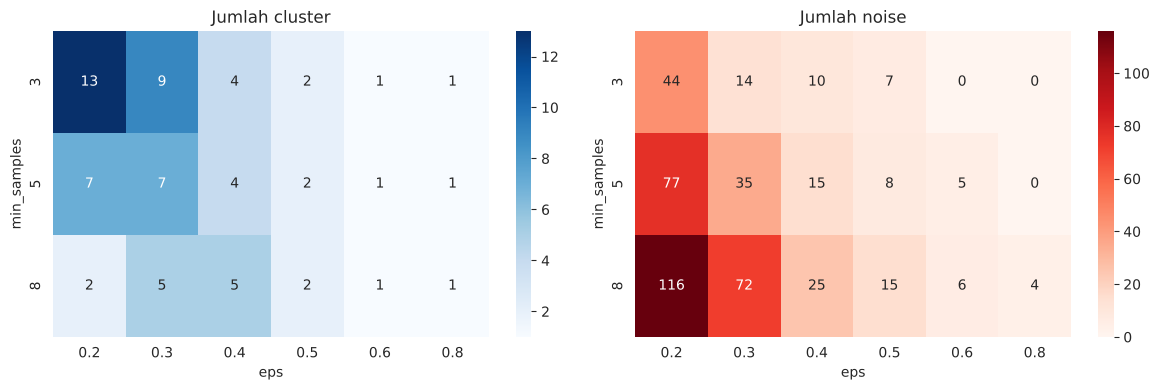

DBSCAN terbaik -> cluster: 5 | noise: 25


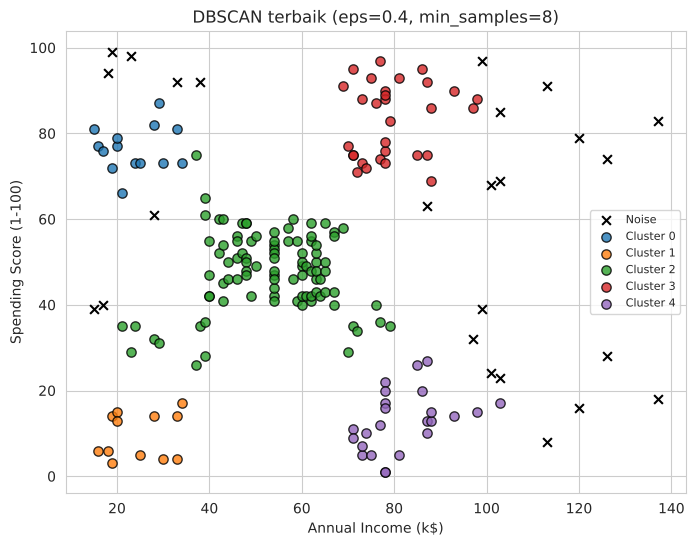

In [11]:
# grafik k-distance untuk membantu memilih eps (k = min_samples = 5)
nn = NearestNeighbors(n_neighbors=5).fit(X_scaled)
jarak, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(jarak[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.title("k-distance plot (k=5)")
plt.xlabel("Titik (diurutkan)")
plt.ylabel("Jarak ke tetangga ke-5")
plt.show()

# coba beberapa kombinasi eps dan min_samples
hasil = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    for ms in [3, 5, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).sum()
        mask = lab != -1
        # silhouette hanya valid kalau ada minimal 2 cluster
        sil = silhouette_score(X_scaled[mask], lab[mask]) if k >= 2 else np.nan
        hasil.append([eps, ms, k, noise, sil])

tabel_dbscan = pd.DataFrame(hasil, columns=["eps", "min_samples", "jumlah_cluster", "jumlah_noise", "silhouette"])
display(tabel_dbscan.round(4))

# heatmap jumlah cluster dan noise
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(tabel_dbscan.pivot(index="min_samples", columns="eps", values="jumlah_cluster"), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Jumlah cluster")
sns.heatmap(tabel_dbscan.pivot(index="min_samples", columns="eps", values="jumlah_noise"), annot=True, fmt="d", cmap="Reds", ax=axes[1])
axes[1].set_title("Jumlah noise")
plt.tight_layout()
plt.show()

# DBSCAN terbaik: dipilih eps=0.4, min_samples=8 (5 cluster, noise masih sedikit, silhouette tinggi)
dbscan_best = DBSCAN(eps=0.4, min_samples=8)
labels_dbscan_best = dbscan_best.fit_predict(X_scaled)
print("DBSCAN terbaik -> cluster:", len(set(labels_dbscan_best)) - 1, "| noise:", (labels_dbscan_best == -1).sum())

fig, ax = plt.subplots(figsize=(8, 6))
plot_cluster(ax, X, labels_dbscan_best, "DBSCAN terbaik (eps=0.4, min_samples=8)")
plt.show()


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**
- **Pengaruh `eps`:** semakin besar `eps`, tetangga yang dijangkau makin luas sehingga noise berkurang tetapi cluster mulai menyatu. Contoh dengan `min_samples=5`: eps 0,2 menghasilkan 7 cluster dan 77 noise, eps 0,3 menghasilkan 7 cluster dan 35 noise, eps 0,4 menghasilkan 4 cluster dan 15 noise, eps 0,5 menghasilkan 2 cluster dan 8 noise.
- **Pengaruh `min_samples`:** semakin besar `min_samples`, syarat menjadi core point makin ketat sehingga noise bertambah. Contoh pada eps 0,3: `min_samples=3` menghasilkan 14 noise, sedangkan `min_samples=8` menghasilkan 72 noise.
- **Kombinasi bermasalah:** eps 0,6 ke atas hanya menghasilkan satu cluster besar (silhouette tidak bisa dihitung), jadi tidak berguna untuk segmentasi. Di sisi lain, eps 0,2 dengan `min_samples=8` menghasilkan hanya 2 cluster dan 116 noise (lebih dari separuh data), terlalu banyak noise. Silhouette-nya tinggi (0,60) tetapi itu menyesatkan karena hanya dihitung pada sisa titik non-noise.
- **Pilihan:** saya memilih `eps=0.4` dan `min_samples=8`: 5 cluster, 25 noise, silhouette 0,549. Jumlah cluster sesuai pola yang terlihat di scatter plot dan noise masih wajar.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster di CF-tree:", len(birch.subcluster_centers_))
print("Label unik BIRCH:", np.unique(labels_birch))


Jumlah subcluster di CF-tree: 10
Label unik BIRCH: [0 1 2 3 4]


In [13]:
print("Jumlah anggota tiap cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())
print("Jumlah cluster:", len(set(labels_birch)))


Jumlah anggota tiap cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


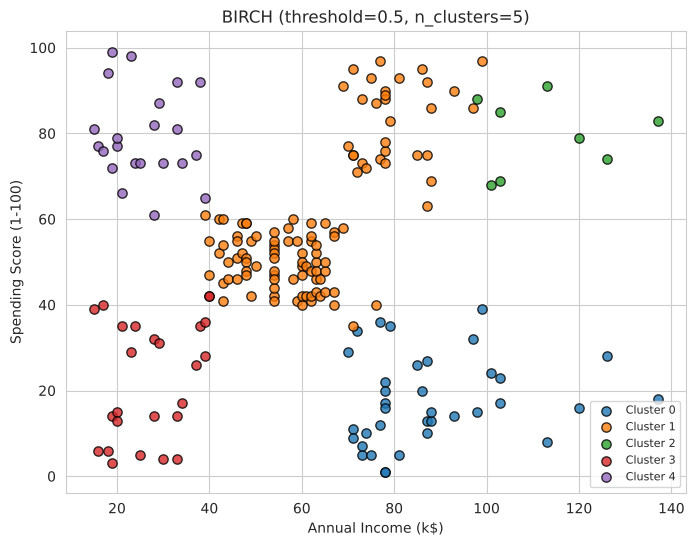

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_cluster(ax, X, labels_birch, "BIRCH (threshold=0.5, n_clusters=5)")
plt.show()


,threshold,jumlah_subcluster,jumlah_cluster_akhir,silhouette
0,0.3,23,5,0.4781
1,0.5,10,5,0.4145
2,0.7,6,5,0.4207
3,1.0,4,4,0.3886


,threshold,n_clusters,jumlah_cluster_akhir,silhouette
0,0.3,None,23,0.4143
1,0.3,3,3,0.4666
2,0.3,5,5,0.4781
3,0.3,7,7,0.5385
4,0.5,None,10,0.4774
5,0.5,3,3,0.3382
6,0.5,5,5,0.4145
7,0.5,7,7,0.5217
8,0.7,None,6,0.4861
9,0.7,3,3,0.4610


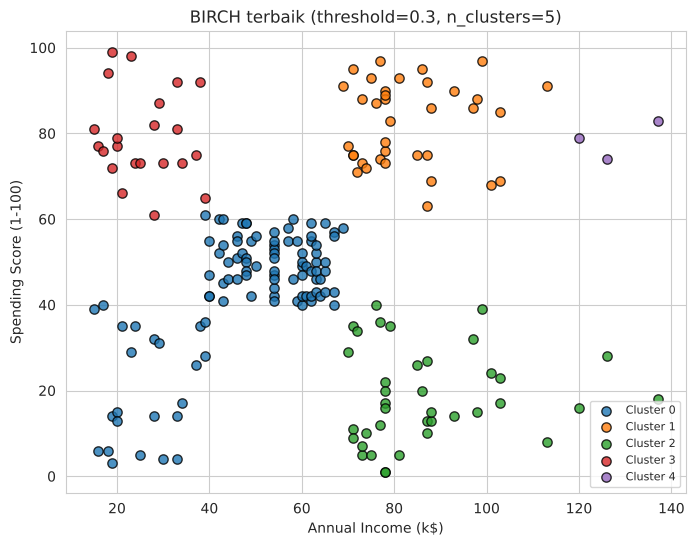

In [15]:
hasil = []
for th in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=th, n_clusters=5).fit(X_scaled)
    lab = b.labels_
    k = len(set(lab))
    sil = silhouette_score(X_scaled, lab) if k >= 2 else np.nan
    hasil.append([th, len(b.subcluster_centers_), k, sil])
tabel_birch = pd.DataFrame(hasil, columns=["threshold", "jumlah_subcluster", "jumlah_cluster_akhir", "silhouette"])
display(tabel_birch.round(4))

# efek n_clusters: tanpa n_clusters (None) vs n_clusters=5, threshold sama
hasil2 = []
for th in [0.3, 0.5, 0.7]:
    for nc in [None, 3, 5, 7]:
        b = Birch(threshold=th, n_clusters=nc).fit(X_scaled)
        lab = b.labels_
        k = len(set(lab))
        sil = silhouette_score(X_scaled, lab) if 2 <= k < len(X_scaled) else np.nan
        hasil2.append([th, str(nc), k, sil])
tabel_birch2 = pd.DataFrame(hasil2, columns=["threshold", "n_clusters", "jumlah_cluster_akhir", "silhouette"])
display(tabel_birch2.round(4))

# BIRCH terbaik: threshold 0.3 dengan n_clusters=5 (silhouette tertinggi)
birch_best = Birch(threshold=0.3, n_clusters=5)
labels_birch_best = birch_best.fit_predict(X_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
plot_cluster(ax, X, labels_birch_best, "BIRCH terbaik (threshold=0.3, n_clusters=5)")
plt.show()


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**
- **Threshold diperbesar:** jumlah subcluster di CF-tree makin sedikit (threshold 0,3 menghasilkan 23 subcluster, 0,5 menghasilkan 10, 0,7 menghasilkan 6, 1,0 hanya 4) karena titik yang lebih jauh pun boleh digabung ke subcluster yang sama. Pada threshold 1,0 subcluster (4) lebih sedikit dari `n_clusters=5`, sehingga hasil akhirnya hanya 4 cluster (muncul peringatan dari sklearn).
- **Perbedaan dengan DBSCAN pada titik yang jauh:** DBSCAN bisa menandai titik jauh sebagai noise (-1), sedangkan BIRCH tidak punya label noise sehingga semua titik dipaksa masuk suatu cluster. Pada BIRCH terbaik (threshold 0,3), titik-titik dengan income sangat tinggi akhirnya menjadi cluster kecil sendiri (hanya 3 anggota), sedangkan pada DBSCAN titik seperti itu dibuang sebagai noise.
- **Pengaruh `n_clusters`:** ya, hasilnya berubah. Jika `n_clusters=None`, cluster akhir sama dengan jumlah subcluster (threshold 0,3 menghasilkan 23 cluster, terlalu banyak). Jika `n_clusters` diisi, subcluster digabung lagi sampai jumlah yang diminta, dan silhouette ikut berubah (threshold 0,3: 3 cluster = 0,467; 5 cluster = 0,478; 7 cluster = 0,539). Saya tetap memakai 5 cluster karena sesuai pola visual data; silhouette 7 cluster yang lebih tinggi kemungkinan hanya karena memecah kelompok besar.
- **Pilihan:** `threshold=0.3` dengan `n_clusters=5` (silhouette tertinggi di antara threshold yang dicoba, 0,478).

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Konvergen:", gmm.converged_, "| jumlah iterasi EM:", gmm.n_iter_)
print("Bobot tiap komponen:", gmm.weights_.round(3))


Konvergen: True | jumlah iterasi EM: 5
Bobot tiap komponen: [0.413 0.197 0.104 0.166 0.121]


In [17]:
print("Jumlah anggota tiap cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba, columns=[f"P(C{k})" for k in range(5)]).round(3)
print("\n10 baris pertama probabilitas keanggotaan:")
display(df_proba.head(10))

# titik yang keanggotaannya tidak pasti (probabilitas maksimum < 0.9)
max_proba = proba.max(axis=1)
ragu = max_proba < 0.9
print("Jumlah titik dengan probabilitas maksimum < 0.9:", ragu.sum())
print("Jumlah titik dengan probabilitas maksimum < 0.7:", (max_proba < 0.7).sum())
display(pd.concat([X[ragu], df_proba[ragu]], axis=1).head(10))


Jumlah anggota tiap cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

10 baris pertama probabilitas keanggotaan:


,P(C0),P(C1),P(C2),P(C3),P(C4)
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000


Jumlah titik dengan probabilitas maksimum < 0.9: 8
Jumlah titik dengan probabilitas maksimum < 0.7: 4


,Annual Income (k$),Spending Score (1-100),P(C0),P(C1),P(C2),P(C3),P(C4)
27,28,61,0.279,0.000,0.675,0.000,0.046
45,39,65,0.822,0.007,0.157,0.000,0.014
47,40,47,0.891,0.000,0.001,0.000,0.108
48,40,42,0.611,0.000,0.000,0.000,0.388
49,40,42,0.611,0.000,0.000,0.000,0.388
55,43,41,0.796,0.000,0.000,0.000,0.204
124,70,29,0.497,0.000,0.000,0.503,0.000
160,79,35,0.772,0.000,0.000,0.228,0.000


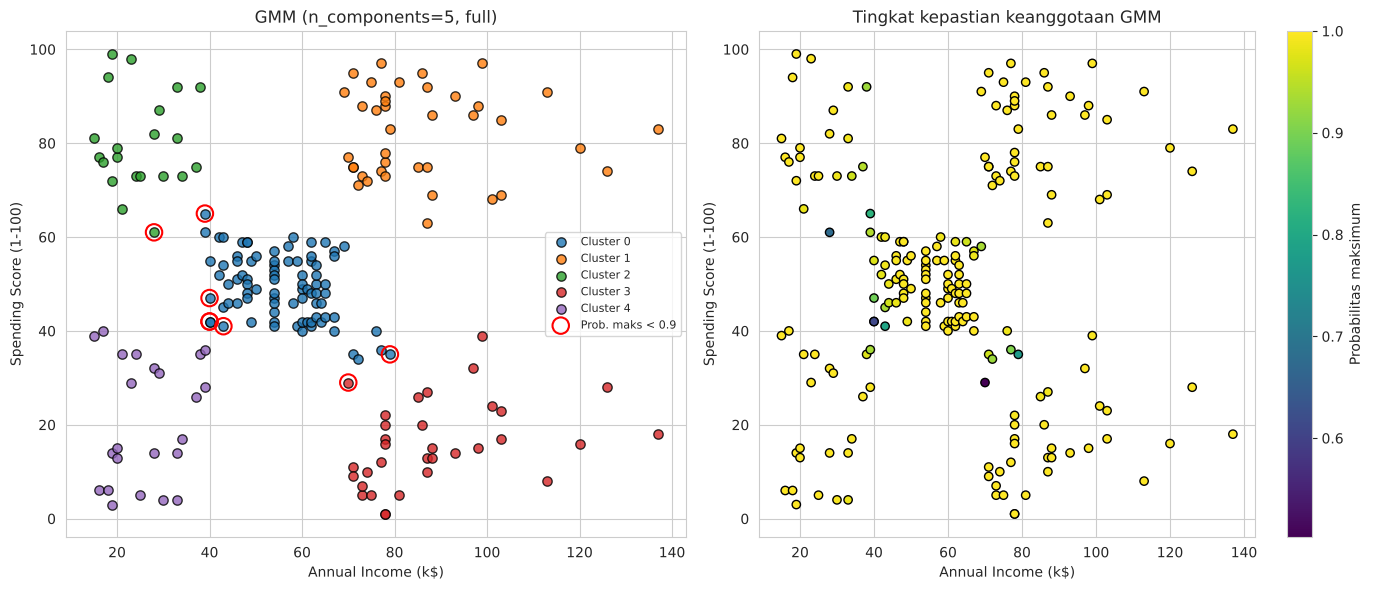

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_cluster(axes[0], X, labels_gmm, "GMM (n_components=5, full)")
# titik ragu-ragu ditandai
axes[0].scatter(X[ragu].iloc[:, 0], X[ragu].iloc[:, 1], facecolors="none", edgecolors="red", s=140, linewidths=1.5, label="Prob. maks < 0.9")
axes[0].legend(fontsize=8)

sc = axes[1].scatter(X.iloc[:, 0], X.iloc[:, 1], c=max_proba, cmap="viridis", edgecolor="k")
plt.colorbar(sc, ax=axes[1], label="Probabilitas maksimum")
axes[1].set_title("Tingkat kepastian keanggotaan GMM")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()


,n_components,silhouette,BIC
0,2,0.3791,1153.9047
1,3,0.4302,1151.7183
2,4,0.4134,1103.7901
3,5,0.5537,1058.6523
4,6,0.5170,1074.6828
5,7,0.5091,1087.3285
6,8,0.4302,1102.3707


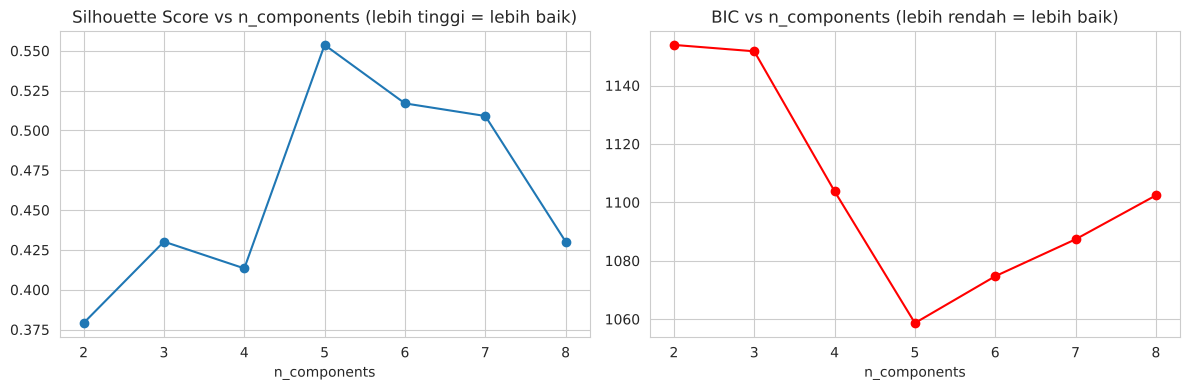

n_components dengan silhouette tertinggi: 5
n_components dengan BIC terendah: 5


In [19]:
hasil = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    hasil.append([k, silhouette_score(X_scaled, lab), g.bic(X_scaled)])
tabel_gmm = pd.DataFrame(hasil, columns=["n_components", "silhouette", "BIC"])
display(tabel_gmm.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tabel_gmm["n_components"], tabel_gmm["silhouette"], marker="o")
axes[0].set_title("Silhouette Score vs n_components (lebih tinggi = lebih baik)")
axes[0].set_xlabel("n_components")
axes[1].plot(tabel_gmm["n_components"], tabel_gmm["BIC"], marker="o", color="red")
axes[1].set_title("BIC vs n_components (lebih rendah = lebih baik)")
axes[1].set_xlabel("n_components")
plt.tight_layout()
plt.show()

print("n_components dengan silhouette tertinggi:", tabel_gmm.loc[tabel_gmm["silhouette"].idxmax(), "n_components"])
print("n_components dengan BIC terendah:", tabel_gmm.loc[tabel_gmm["BIC"].idxmin(), "n_components"])


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**
- **Probabilitas keanggotaan:** nilai ini menunjukkan seberapa besar kemungkinan suatu titik berasal dari tiap komponen Gaussian (jumlah per baris = 1). Ini disebut *soft clustering*. Sebagian besar titik punya probabilitas hampir 1 pada satu cluster, tetapi ada 8 titik dengan probabilitas maksimum di bawah 0,9 (4 titik di bawah 0,7), yaitu titik di perbatasan antar cluster, misalnya income 70 dengan spending 29 yang probabilitasnya 0,497 vs 0,503.
- **Perubahan `n_components`:** jumlah komponen menentukan banyaknya cluster. Terlalu sedikit membuat kelompok berbeda tergabung (n=2 atau 3 silhouette rendah), terlalu banyak membuat cluster besar terpecah tanpa makna (n=8 silhouette turun ke 0,43 dan BIC naik).
- **Mengapa jumlah cluster harus ditentukan di awal:** karena GMM adalah model dengan jumlah komponen tetap; EM hanya mengestimasi parameter (mean, kovarians, bobot) untuk K komponen yang sudah ditentukan, bukan mencari K sendiri. Karena itu K dipilih dengan membandingkan model, misalnya lewat BIC.
- **Silhouette tertinggi vs BIC terendah:** pada data ini keduanya menunjuk `n_components=5` (silhouette 0,554; BIC 1058,65), jadi konsisten.
- **Cara kerja EM:** pada E-step dihitung probabilitas keanggotaan tiap titik dengan parameter saat ini. Pada M-step parameter (mean, kovarians, bobot) diperbarui memakai probabilitas tersebut sebagai bobot. Dua langkah ini diulang sampai konvergen.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
def evaluasi(X_data, labels, nama):
    """hitung metrik internal; untuk DBSCAN titik noise (-1) dikeluarkan dulu"""
    labels = np.asarray(labels)
    mask = labels != -1
    Xe, le = np.asarray(X_data)[mask], labels[mask]
    n_cluster = len(set(le))
    n_noise = int((~mask).sum())
    hasil = {"model": nama, "jumlah_cluster": n_cluster, "jumlah_noise": n_noise,
             "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    # metrik hanya valid kalau minimal 2 cluster dan cluster < jumlah titik
    if n_cluster >= 2 and n_cluster < len(Xe):
        hasil["silhouette"] = silhouette_score(Xe, le)
        hasil["davies_bouldin"] = davies_bouldin_score(Xe, le)
        hasil["calinski_harabasz"] = calinski_harabasz_score(Xe, le)
    return hasil


,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
model,,,,,
DBSCAN,5,25,0.5490,0.5015,222.0651
BIRCH,5,0,0.4781,0.6477,144.0135
EM/GMM,5,0,0.5537,0.5760,244.9402


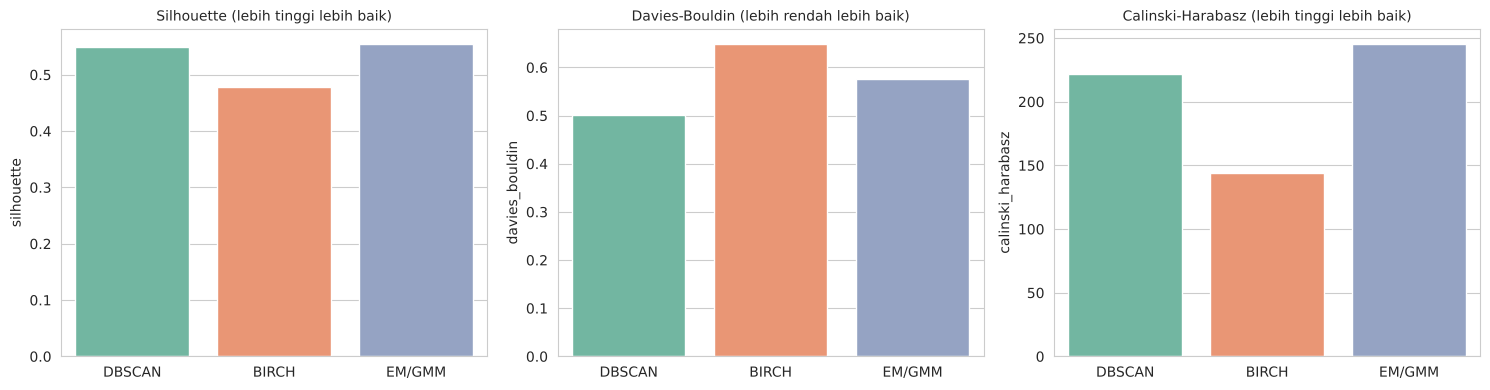

In [21]:
# model terbaik: DBSCAN (eps=0.4, min_samples=8), BIRCH (threshold=0.3, n_clusters=5), GMM (n=5, full)
labels_gmm_best = labels_gmm  # GMM dengan 5 komponen sudah yang terbaik (silhouette tertinggi & BIC terendah)

tabel_eval = pd.DataFrame([
    evaluasi(X_scaled, labels_dbscan_best, "DBSCAN"),
    evaluasi(X_scaled, labels_birch_best, "BIRCH"),
    evaluasi(X_scaled, labels_gmm_best, "EM/GMM"),
]).set_index("model")
display(tabel_eval.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kol, jdl in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                        ["Silhouette (lebih tinggi lebih baik)", "Davies-Bouldin (lebih rendah lebih baik)", "Calinski-Harabasz (lebih tinggi lebih baik)"]):
    sns.barplot(x=tabel_eval.index, y=tabel_eval[kol], ax=ax, palette="Set2")
    ax.set_title(jdl, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


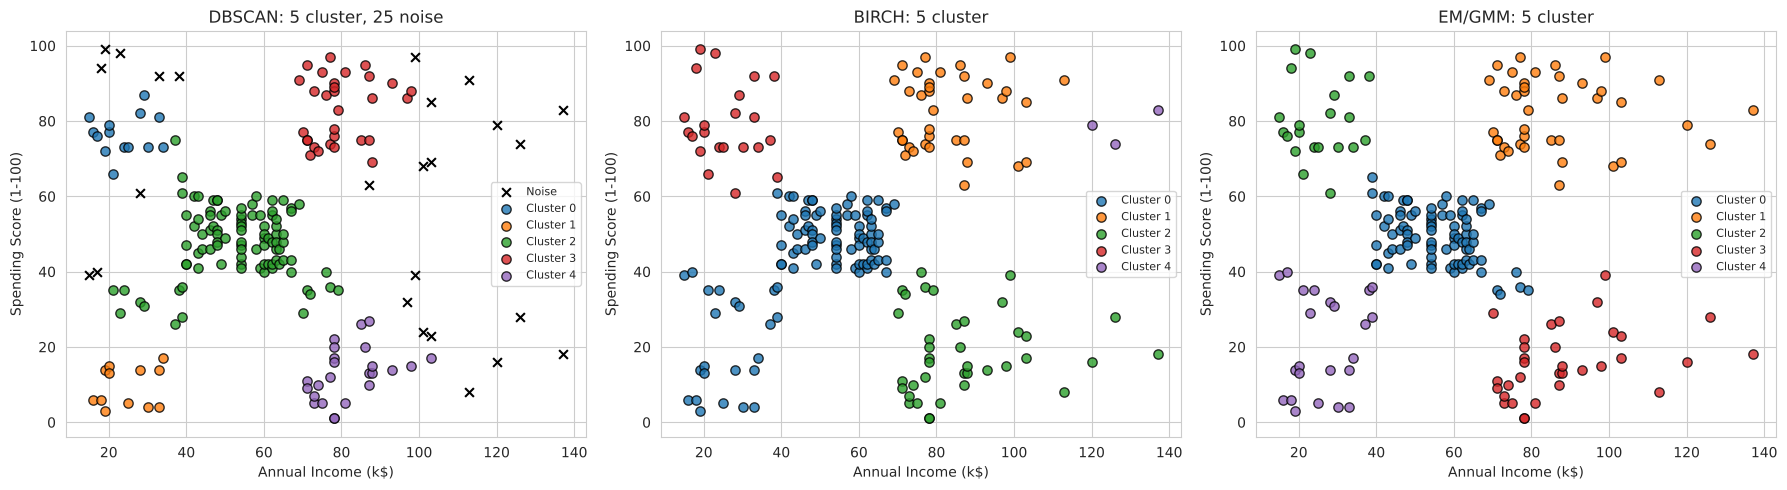

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
n_db = len(set(labels_dbscan_best)) - 1
plot_cluster(axes[0], X, labels_dbscan_best, f"DBSCAN: {n_db} cluster, {(labels_dbscan_best == -1).sum()} noise")
plot_cluster(axes[1], X, labels_birch_best, f"BIRCH: {len(set(labels_birch_best))} cluster")
plot_cluster(axes[2], X, labels_gmm_best, f"EM/GMM: {len(set(labels_gmm_best))} cluster")
plt.tight_layout()
plt.show()


In [23]:
def profil(labels, nama):
    d = X.copy()
    d["cluster"] = labels
    p = d.groupby("cluster").agg(
        jumlah=("cluster", "size"),
        income_mean=("Annual Income (k$)", "mean"),
        income_median=("Annual Income (k$)", "median"),
        spending_mean=("Spending Score (1-100)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
    ).round(1)
    print(f"===== Profil cluster {nama} (cluster -1 = noise) =====")
    display(p)
    return p

p_db = profil(labels_dbscan_best, "DBSCAN")
p_bi = profil(labels_birch_best, "BIRCH")
p_gm = profil(labels_gmm_best, "EM/GMM")

# interpretasi tambahan: komposisi Gender per cluster GMM (Gender bukan input model)
print("Komposisi Gender per cluster GMM:")
display(pd.crosstab(labels_gmm_best, df["Gender"], normalize="index").round(2))


===== Profil cluster DBSCAN (cluster -1 = noise) =====


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
-1,25,83.0,101.0,60.5,68.0
0,14,23.6,22.5,76.4,76.5
1,12,24.6,22.5,9.6,9.5
2,95,53.3,54.0,47.8,48.0
3,30,79.5,78.0,83.1,86.0
4,24,81.9,78.0,13.0,13.0


===== Profil cluster BIRCH (cluster -1 = noise) =====


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
0,101,48.2,50.0,43.4,47.0
1,36,83.1,78.0,82.4,85.5
2,38,87.0,80.0,18.6,16.5
3,22,25.7,24.5,79.4,77.0
4,3,127.7,126.0,78.7,79.0


===== Profil cluster EM/GMM (cluster -1 = noise) =====


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
0,84,55.6,55.5,49.4,49.5
1,39,86.5,79.0,82.1,83.0
2,21,25.1,24.0,80.0,77.0
3,33,88.8,86.0,16.0,15.0
4,23,26.3,25.0,20.9,17.0


Komposisi Gender per cluster GMM:


Gender,Female,Male
row_0,,
0,0.60,0.40
1,0.54,0.46
2,0.57,0.43
3,0.45,0.55
4,0.61,0.39


### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak, jumlah cluster hasil dari `eps` dan `min_samples` | Opsional: `n_clusters` bisa diisi atau `None` (cluster = subcluster) | Ya, `n_components` harus ditentukan |
| Dapat memberi label noise secara eksplisit? | Ya (label -1; 25 titik pada hasil terbaik) | Tidak | Tidak (tetapi ada probabilitas, titik ragu-ragu bisa dikenali) |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas (berdasarkan kepadatan) | Cenderung bulat (berbasis jarak ke centroid subcluster) | Elips (Gaussian dengan kovarians) |
| Kelebihan | Tahan terhadap outlier, bentuk cluster fleksibel, tidak perlu K | Cepat dan hemat memori, cocok untuk data besar | Ada probabilitas keanggotaan, cluster bisa tumpang tindih, ada BIC untuk memilih K |
| Kekurangan | Sensitif terhadap `eps`/`min_samples`, sebagian data jadi noise | Semua titik dipaksa masuk cluster, hasil sensitif terhadap `threshold` | Asumsi Gaussian, harus menentukan K, bisa bergantung inisialisasi |


# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

### Jawaban

1. **Scaling:** DBSCAN, BIRCH, dan GMM bergantung pada jarak/kovarians sehingga fitur dengan skala besar bisa mendominasi. Pada data ini skala income dan spending sudah mirip (std 26,3 vs 25,8), sehingga bentuk sebaran tidak banyak berubah. Namun scaling membuat `eps` dan `threshold` bermakna dalam satuan standar deviasi, dan menjadi praktik wajib jika nanti ditambah fitur lain seperti Age.
2. **DBSCAN:** `eps` naik menyebabkan noise turun dan cluster menyatu (eps 0,2 ke 0,6 dengan `min_samples=5`: noise 77 ke 5, cluster 7 ke 1). `min_samples` naik menyebabkan noise naik (eps 0,3: `min_samples` 3 ke 8 membuat noise 14 ke 72).
3. **BIRCH:** `threshold` naik membuat subcluster makin sedikit (23 ke 4). `n_clusters` menentukan penggabungan akhir; jika `None`, jumlah cluster sama dengan subcluster (23 pada threshold 0,3), jika diisi 5 hasilnya 5 cluster. Jika subcluster kurang dari `n_clusters`, jumlah cluster akhir lebih sedikit dari yang diminta (threshold 1,0).
4. **Probabilitas GMM:** menyatakan kemungkinan suatu titik berasal dari tiap komponen. EM memakai probabilitas ini (E-step) sebagai bobot untuk memperbarui mean, kovarians, dan bobot komponen (M-step), diulang sampai konvergen.
5. **Paling mudah diinterpretasikan:** menurut saya EM/GMM. Semua pelanggan masuk ke salah satu dari 5 cluster yang sangat mirip dengan 5 kelompok yang terlihat di scatter plot, dan tiap pelanggan punya probabilitas keanggotaan. DBSCAN terbaik juga mudah dibaca (5 cluster), tetapi 25 titik menjadi noise sehingga perlu penjelasan tambahan. BIRCH menghasilkan cluster dengan ukuran sangat timpang (101, 38, 36, 22, dan 3 anggota).
6. **Metrik:** tidak semuanya menunjuk model yang sama. Silhouette dan Calinski-Harabasz tertinggi dimiliki GMM (0,554 dan 244,9), sedangkan Davies-Bouldin terbaik (terendah) dimiliki DBSCAN (0,502). Kemungkinan penyebabnya: metrik DBSCAN dihitung tanpa 25 titik noise sehingga cluster tampak lebih rapat dan terpisah, dan tiap metrik punya cara hitung berbeda (DB melihat rasio sebaran terhadap jarak antar cluster, CH melihat rasio varians). BIRCH paling rendah di ketiga metrik.
7. **Karakteristik cluster (GMM, berdasarkan median):**
   - Cluster 0 (84 pelanggan): income sekitar 55 k$, spending 49. **Pelanggan menengah/rata-rata.**
   - Cluster 1 (39): income sekitar 79 k$, spending 83. **Kaya dan boros (target utama promosi).**
   - Cluster 2 (21): income sekitar 24 k$, spending 77. **Berpendapatan rendah tetapi royal.**
   - Cluster 3 (33): income sekitar 86 k$, spending 15. **Berpendapatan tinggi tetapi hemat.**
   - Cluster 4 (23): income sekitar 25 k$, spending 17. **Berpendapatan rendah dan hemat.**

   Komposisi Gender di tiap cluster cukup seimbang (perempuan 45% sampai 61%), sehingga Gender tidak terlalu membedakan cluster.
8. **Keterbatasan:** hanya dua fitur, sehingga informasi lain seperti Age, Gender, dan kebiasaan belanja tidak ikut terlihat. Data hanya 200 pelanggan sehingga hasil parameter (terutama `eps` dan `min_samples`) mudah berubah dan bisa sekadar menyesuaikan data ini. Metrik internal tidak membuktikan bahwa cluster bermakna secara bisnis (tidak ada label sebenarnya), dan GMM diasumsikan berbentuk Gaussian.


# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

### Jawaban

- **Algoritma paling berguna:** EM/GMM dengan 5 komponen. Silhouette (0,554) dan Calinski-Harabasz (244,9) tertinggi, BIC terendah di n=5, semua pelanggan terklasifikasi, dan 5 cluster yang dihasilkan mudah dinamai. DBSCAN terbaik hampir sama bagusnya (silhouette 0,549 dan Davies-Bouldin terbaik 0,502), tetapi 25 pelanggan (12,5%) dianggap noise.
- **Parameter yang dipilih:** DBSCAN `eps=0.4` dan `min_samples=8` (5 cluster dengan noise wajar); BIRCH `threshold=0.3` dan `n_clusters=5` (silhouette tertinggi); GMM `n_components=5`, `covariance_type='full'`, `random_state=42` (silhouette tertinggi dan BIC terendah).
- **Perbedaan utama:** DBSCAN berbasis kepadatan dan bisa memberi noise tanpa perlu K; BIRCH berbasis ringkasan pohon (cepat, tetapi hasilnya paling lemah di sini dan semua titik dipaksa masuk cluster); GMM berbasis probabilitas sehingga bisa menunjukkan titik yang berada di perbatasan cluster.
- **Eksperimen lanjutan:** menambahkan fitur Age (3 fitur) dan membandingkan hasil, mencoba `covariance_type` lain (`tied`, `diag`, `spherical`), membandingkan dengan K-Means atau Hierarchical Clustering, dan menguji kestabilan hasil dengan `random_state` yang berbeda.


## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)